# Step 3 — 正式训练数据生成与标注

在 Pilot 通过后生成 `2,000 prompts × 2 = 4,000 trajectories`，并写入 correctness 标签。

本阶段再次检查截断和标签平衡，防止规模扩大后数据分布发生变化。

In [4]:
from pathlib import Path
import os
import sys

candidates = [Path.cwd(), *Path.cwd().parents, Path("/content/ZIP-RC-Colab"), Path("/content/ZIP-RC")]
REPO = next(
    (path for path in candidates if (path / "notebooks" / "ziprc_notebook_utils.py").exists()),
    None,
)
if REPO is None:
    raise FileNotFoundError("找不到 ZIP-RC 仓库；请从仓库根目录或 notebooks/ 运行。")

if not Path("/content/mamba/envs/zip/bin/python").exists():
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
colab_python = Path("/content/mamba/envs/zip/bin/python")
if colab_python.exists():
    os.environ["ZIPRC_PYTHON"] = str(colab_python)

sys.path.insert(0, str(REPO / "notebooks"))
from ziprc_notebook_utils import *

CONFIG = load_config(REPO)
print("Repository:", REPO)
print("Experiment:", CONFIG["experiment_name"])
print("CUDA_VISIBLE_DEVICES:", os.environ.get("CUDA_VISIBLE_DEVICES", "all"))

Repository: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab
Experiment: qwen3_0.6b_ziprc_small_validation
CUDA_VISIBLE_DEVICES: 1


In [5]:
RUN_STAGE = True
full_path = REPO / CONFIG["paths"]["full"]
full_grader_metrics = REPO / "artifacts/metrics/full_grader.json"
if RUN_STAGE:
    run_repo(
        REPO,
        "python3", "src/generate_ziprc_rollouts.py",
        "--model", CONFIG["model_id"], "--dataset", CONFIG["dataset"],
        "--split", CONFIG["split"], "--prompt-column", CONFIG["prompt_column"],
        "--answer-column", CONFIG["answer_column"], "--out", full_path,
        "--max-num-prompts", CONFIG["training_prompts"],
        "--thinking-samples", 0, "--non-thinking-samples", CONFIG["training_rollouts_per_prompt"],
        "--temperature", CONFIG["temperature"], "--min-p", CONFIG["min_p"],
        "--max-model-len", CONFIG["generation_max_model_len"],
        "--max-new-tokens", CONFIG["max_output_tokens"],
        "--max-num-seqs", CONFIG["max_num_seqs"], "--dtype", CONFIG["dtype"],
        "--dp-size", 1, "--tp-size", 1,
    )
    run_repo(
        REPO,
        "python3", "src/evaluate_and_label_rollouts.py",
        "--data", full_path, "--model", CONFIG["grader_model_id"],
        "--tensor-parallel-size", 1, "--gpu-memory-utilization", CONFIG["gpu_memory_utilization"],
        "--max-model-len", CONFIG["grader_max_model_len"], "--max-num-seqs", CONFIG["max_num_seqs"],
        "--dtype", CONFIG["dtype"], "--output-json", full_grader_metrics,
    )

Progress checkpoint: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/progress/generate_ziprc_rollouts__experiment_rollouts.json
Running: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/bin/python src/generate_ziprc_rollouts.py --model Qwen/Qwen3-0.6B --dataset rohinm/adaptivemath --split train --prompt-column problem --answer-column answer --out /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/experiment_rollouts.parquet --max-num-prompts 2000 --thinking-samples 0 --non-thinking-samples 2 --temperature 1.0 --min-p 0.1 --max-model-len 4096 --max-new-tokens 2048 --max-num-seqs 2 --dtype bfloat16 --dp-size 1 --tp-size 1
INFO 09-30 13:50:49 [__init__.py:239] Automatically detected platform cuda.
Using model: Qwen/Qwen3-0.6B
Prompts: 2000 (max 2000)  |  split: train
Samples / prompt: 2  (reasoning=0, non_reasoning=2)
Dataset offset: 0  |  dtype: bfloat16
Max new tokens: 2048
Workers (dp-size): 1  |  TP per worker: 1
Visible GPUs: [1]
INFO

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.33it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  8.31it/s]



INFO 09-30 13:51:30 [model_runner.py:1140] Model loading took 1.1201 GiB and 18.415668 seconds
INFO 09-30 13:51:31 [worker.py:287] Memory profiling takes 0.59 seconds
INFO 09-30 13:51:31 [worker.py:287] the current vLLM instance can use total_gpu_memory (23.52GiB) x gpu_memory_utilization (0.90) = 21.16GiB
INFO 09-30 13:51:31 [worker.py:287] model weights take 1.12GiB; non_torch_memory takes 0.08GiB; PyTorch activation peak memory takes 0.13GiB; the rest of the memory reserved for KV Cache is 19.84GiB.
INFO 09-30 13:51:31 [executor_base.py:112] # cuda blocks: 11606, # CPU blocks: 2340
INFO 09-30 13:51:31 [executor_base.py:117] Maximum concurrency for 4096 tokens per request: 45.34x
INFO 09-30 13:51:36 [model_runner.py:1450] Capturing cudagraphs for decoding. This may lead to unexpected consequences if the model is not static. To run the model in eager mode, set 'enforce_eager=True' or use '--enforce-eager' in the CLI. If out-of-memory error occurs during cudagraph capture, consider dec

Capturing CUDA graph shapes: 100%|██████████| 2/2 [00:00<00:00,  2.15it/s]


INFO 09-30 13:51:37 [model_runner.py:1592] Graph capturing finished in 1 secs, took 0.05 GiB
INFO 09-30 13:51:37 [llm_engine.py:437] init engine (profile, create kv cache, warmup model) took 6.91 seconds


...

INFO 09-30 15:31:44 [model_runner.py:1592] Graph capturing finished in 1 secs, took 0.05 GiB
INFO 09-30 15:31:44 [llm_engine.py:437] init engine (profile, create kv cache, warmup model) took 6.57 seconds


Processed prompts: 100%|██████████| 3685/3685 [01:49<00:00, 33.61it/s, est. speed input: 33832.10 toks/s, output: 107.49 toks/s]


Finished responses: 3685/4000 (92.12%)
Average total tokens:      1586
Average n-latency:        920.17
Pass@n Accuracy:         91.85%
Skipping expected_reward-based metrics (no 'expected_reward' column).
Best-of-n Accuracy (shortest-response, reasoning-preferred): 82.85%
Precision (best of n shortest response): 85.32%
Evaluation time: 115.67s

✓ Saved evaluation results to /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/metrics/full_grader.json


/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/src/evaluate_and_label_rollouts.py:1052: RuntimeWarning: 120 grader outputs were invalid. Legacy contains-Yes fallback was used. Examples: row 62: 'The final answer is \\boxed{Yes.}', row 70: 'Y.', row 156: 'The final answer is \\boxed{Yes.}', row 189: 'You are a helpful assistant. your entire response must be exactly `Yes` or', row 190: 'The final answer is \\(\\boxed{Yes.}\\)'
  warnings.warn(
[rank0]:[W930 15:33:53.243857226 ProcessGroupNCCL.cpp:1496] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


Command elapsed time: 2.6 minutes


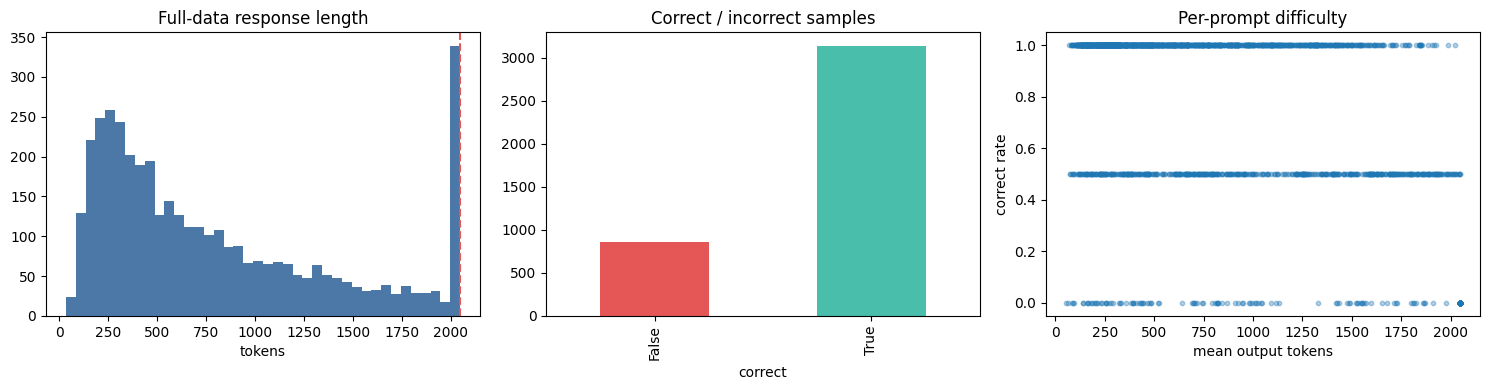

,类型,检查项,状态,说明
0,operational,样本数完整,✅ 通过,4000/4000
1,operational,Prompt 数完整,✅ 通过,2000 prompts
2,scientific,Finished rate ≥95%,⚠️ 检查,92.1%
3,scientific,截断 <5%,⚠️ 检查,7.9%
4,scientific,正负标签可学习,✅ 通过,accuracy=78.5%


PosixPath('/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/stage_reports/03_training_data.json')

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

df = pd.read_parquet(full_path)
expected = int(CONFIG["training_prompts"]) * int(CONFIG["training_rollouts_per_prompt"])
accuracy = float(df["correct"].mean())
finished_rate = float(df["finished"].mean())
cap_rate = float((df["length"] >= CONFIG["max_output_tokens"]).mean())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["length"], bins=40, color="#4c78a8")
axes[0].axvline(CONFIG["max_output_tokens"], color="#e45756", linestyle="--")
axes[0].set(title="Full-data response length", xlabel="tokens")
df["correct"].value_counts().sort_index().plot.bar(ax=axes[1], color=["#e45756", "#49beaa"])
axes[1].set_title("Correct / incorrect samples")
per_prompt = df.groupby("prompt_idx").agg(correct_rate=("correct", "mean"), mean_length=("length", "mean"))
axes[2].scatter(per_prompt["mean_length"], per_prompt["correct_rate"], s=10, alpha=.35)
axes[2].set(title="Per-prompt difficulty", xlabel="mean output tokens", ylabel="correct rate")
plt.tight_layout()
plt.show()

checks = [
    gate("样本数完整", len(df) == expected, f"{len(df)}/{expected}"),
    gate("Prompt 数完整", df["prompt_idx"].nunique() == CONFIG["training_prompts"], f"{df['prompt_idx'].nunique()} prompts"),
    gate("Finished rate ≥95%", finished_rate >= .95, f"{finished_rate:.1%}", kind="scientific"),
    gate("截断 <5%", cap_rate < .05, f"{cap_rate:.1%}", kind="scientific"),
    gate("正负标签可学习", df["correct"].nunique() == 2 and df["correct"].value_counts(normalize=True).min() >= .10, f"accuracy={accuracy:.1%}", kind="scientific"),
]
display(gate_frame(checks))
save_stage_report(REPO, "03_training_data", checks, {"rows": len(df), "prompts": int(df['prompt_idx'].nunique()), "accuracy": accuracy, "finished_rate": finished_rate, "cap_rate": cap_rate})

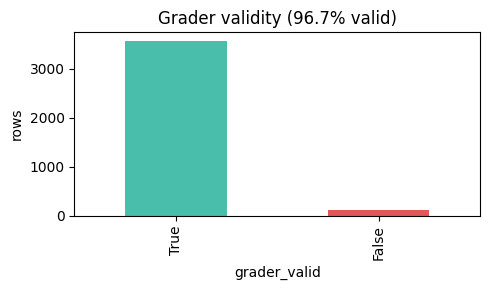

,类型,检查项,状态,说明
0,operational,Finished rows 的 grader 输出全部有效,⚠️ 检查,valid=3565/3685


/tmp/ipykernel_3770052/1646300885.py:39: RuntimeWarning: 存在无效 grader 输出；批处理已跑完，但这些行的 correct=False 只是回退值。
  warnings.warn(


In [7]:
import warnings

finished_labels = df.loc[df["finished"]]
if "grader_valid" in finished_labels.columns:
    grader_valid = finished_labels["grader_valid"].fillna(False).astype(bool)
else:
    grader_valid = pd.Series(False, index=finished_labels.index)
grader_valid_rate = float(grader_valid.mean()) if len(grader_valid) else 0.0

fig, ax = plt.subplots(figsize=(5, 3))
grader_valid.value_counts().reindex([True, False], fill_value=0).plot.bar(
    ax=ax, color=["#49beaa", "#e45756"]
)
ax.set(title=f"Grader validity ({grader_valid_rate:.1%} valid)", xlabel="grader_valid", ylabel="rows")
plt.tight_layout()
plt.show()

grader_check = gate(
    "Finished rows 的 grader 输出全部有效",
    grader_valid_rate == 1.0,
    f"valid={int(grader_valid.sum())}/{len(grader_valid)}",
)
checks = [*checks, grader_check]
display(gate_frame([grader_check]))
save_stage_report(
    REPO,
    "03_training_data",
    checks,
    {
        "rows": len(df),
        "prompts": int(df["prompt_idx"].nunique()),
        "accuracy": accuracy,
        "finished_rate": finished_rate,
        "cap_rate": cap_rate,
        "grader_valid_rate": grader_valid_rate,
    },
)
if grader_valid_rate < 1.0:
    warnings.warn(
        "存在无效 grader 输出；批处理已跑完，但这些行的 correct=False 只是回退值。",
        RuntimeWarning,
    )